# 01. Khám phá Dữ liệu (EDA) — Credit Risk Dataset

**Mục tiêu notebook**:
1. Kiểm tra kích thước, kiểu dữ liệu và bản ghi trùng lặp.
2. Đánh giá mức độ mất cân bằng của biến mục tiêu (`loan_status`).
3. Phân tích giá trị khuyết (`missing values`) và mối liên hệ với rủi ro nợ xấu.
4. Phát hiện ngoại trị (`outliers`) và các lỗi nhập liệu phi logic.
5. Phân tích tỷ lệ nợ xấu theo các biến phân loại và ma trận tương quan biến số.
6. Chốt kế hoạch tiền xử lý cho **Bước 3**.

## 1. Đọc dữ liệu & Kiểm tra tổng quan
Kiểm tra số dòng, số cột, kiểu dữ liệu từng thuộc tính và số lượng bản ghi trùng lặp hoàn toàn trong `credit_risk_dataset.csv`.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/raw/credit_risk_dataset.csv")

print("Kích thước dữ liệu:", df.shape)
print("Số dòng trùng lặp hoàn toàn:", df.duplicated().sum())
display(df.head())
df.info()

Kích thước dữ liệu: (32581, 12)
Số dòng trùng lặp hoàn toàn: 165


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.5 MB


> **Nhận xét Phần 1**:
> - Bộ dữ liệu có `32581` dòng và `12` cột (7 biến số, 4 biến phân loại, 1 biến mục tiêu `loan_status`).
> - Phát hiện `165` dòng trùng lặp hoàn toàn → **Cần xóa trước khi chia tập Train/Test** ở Bước 3 để tránh rò rỉ dữ liệu.

## 2. Phân tích mức độ mất cân bằng nhãn (`loan_status`)
Thống kê tỷ lệ giữa nhóm khách hàng tốt (`0`) và nhóm khách hàng nợ xấu (`1`) để xác định tỷ lệ nợ xấu thực tế ($\pi_{\text{real}}$) và làm cơ sở áp dụng **SMOTE**.

             Số lượng  Tỷ lệ (%)
loan_status                     
0               25473      78.18
1                7108      21.82


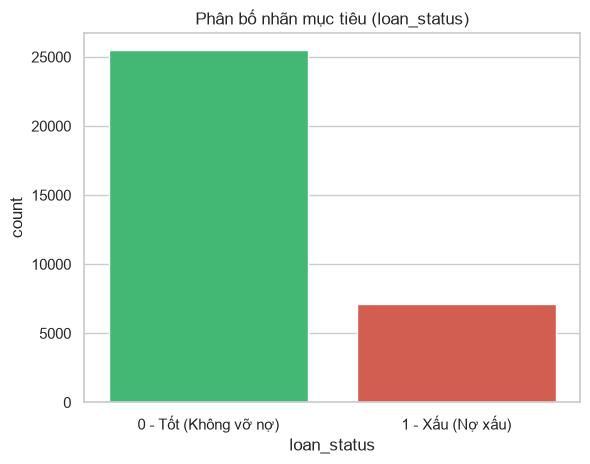

In [14]:
target_counts = df["loan_status"].value_counts()
target_pct = df["loan_status"].value_counts(normalize=True) * 100
print(pd.DataFrame({"Số lượng": target_counts, "Tỷ lệ (%)": target_pct.round(2)}))

ax = sns.countplot(data=df, x="loan_status", hue="loan_status", palette=["#2ecc71", "#e74c3c"], legend=False)
ax.set_xticks([0, 1], ["0 - Tốt (Không vỡ nợ)", "1 - Xấu (Nợ xấu)"])
ax.set_title("Phân bố nhãn mục tiêu (loan_status)")
plt.savefig("../reports/figures/eda_target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

> **Nhận xét Phần 2**:
> - Tỷ lệ lớp `0` (Tốt): `78.18%` | Tỷ lệ lớp `1` (Nợ xấu): `21.82%`.
> - Dữ liệu mất cân bằng rõ rệt → Không đánh giá bằng `Accuracy`, tập trung vào **ROC-AUC, Gini, F1-Score, Recall** và áp dụng **SMOTE bên trong Pipeline CV** ở Bước 3.

## 3. Phân tích giá trị khuyết (Missing Values)
Xác định các cột bị thiếu dữ liệu, tỷ lệ khuyết, đồng thời so sánh tỷ lệ nợ xấu giữa nhóm **bị khuyết** và **không bị khuyết** để quyết định có cần thêm cờ đánh dấu (`missing indicator`) hay không.

In [ ]:
missing = pd.DataFrame({
    "Số lượng khuyết": df.isna().sum(),
    "Tỷ lệ khuyết (%)": (df.isna().mean() * 100).round(2)
})
display(missing[missing["Số lượng khuyết"] > 0])

# So sánh tỷ lệ nợ xấu giữa nhóm khuyết vs không khuyết
for col in ["person_emp_length", "loan_int_rate"]:
    print(f"\nTỷ lệ nợ xấu theo trạng thái khuyết của {col}:")
    print(df.groupby(df[col].isna())["loan_status"].mean().round(4))

,Số lượng khuyết,Tỷ lệ khuyết (%)
person_emp_length,895,2.75
loan_int_rate,3116,9.56



Tỷ lệ nợ xấu theo trạng thái khuyết của person_emp_length:
person_emp_length
False    0.2154
True     0.3151
Name: loan_status, dtype: float64

Tỷ lệ nợ xấu theo trạng thái khuyết của loan_int_rate:
loan_int_rate
False    0.2194
True     0.2067
Name: loan_status, dtype: float64


> **Nhận xét Phần 3**:
> - Có 2 cột bị khuyết: `person_emp_length` (`2.75%`) và `loan_int_rate` (`9.56%`).
> - So sánh tỷ lệ nợ xấu giữa nhóm khuyết và không khuyết: `[ghi nhận chênh lệch thấy được]`.
> - **Hướng xử lý**: Điền bằng `Median` (fit trên tập Train) để bền vững với ngoại trị, cân nhắc bật `add_indicator=True`.

## 4. Phân tích phân phối & Phát hiện ngoại trị (Outliers / Lỗi nhập liệu)
Kiểm tra thống kê mô tả (`describe`), vẽ biểu đồ `Boxplot` cho 7 biến số và phát hiện các giá trị bất hợp lý về mặt logic (tuổi > 100, số năm kinh nghiệm > 60 hoặc lớn hơn tuổi).

,count,mean,std,min,1%,25%,50%,75%,99%,max
person_age,32581.0,27.734600,6.348078,20.00,21.00,23.00,26.00,30.00,50.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,14400.00,38500.00,55000.00,79200.00,225200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,0.00,2.00,4.00,7.00,18.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,1000.00,5000.00,8000.00,12200.00,29800.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,5.42,7.90,10.99,13.47,18.62,23.22
loan_percent_income,32581.0,0.170203,0.106782,0.00,0.02,0.09,0.15,0.23,0.50,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.00,2.00,3.00,4.00,8.00,17.00,30.00


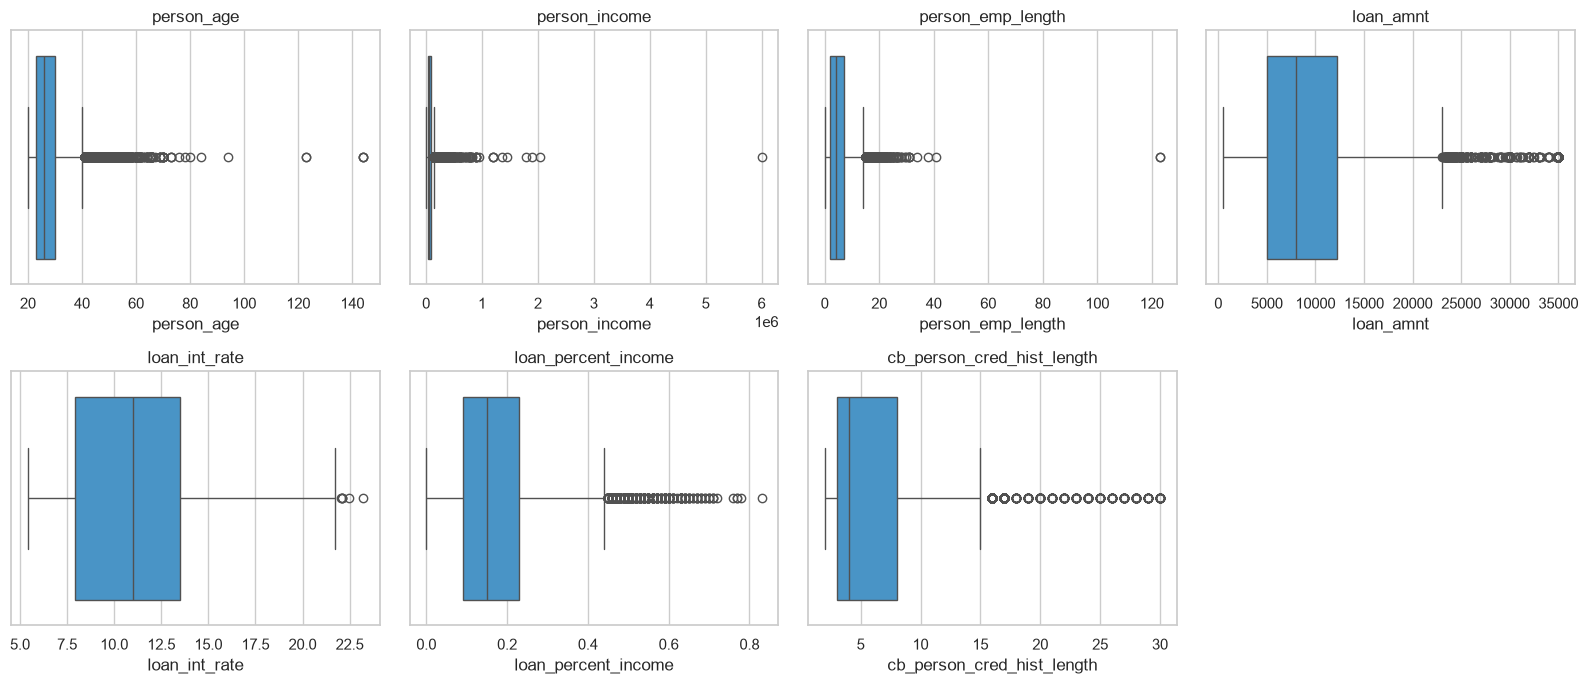

Số dòng person_age > 100: 5
Số dòng person_emp_length > 60: 2
Số dòng person_emp_length > person_age: 2


In [10]:
num_cols = [
    "person_age", "person_income", "person_emp_length",
    "loan_amnt", "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length"
]
display(df[num_cols].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(x=df[col], ax=ax, color="#3498db")
    ax.set_title(col)
axes.flatten()[-1].axis("off")
plt.tight_layout()
plt.savefig("../reports/figures/eda_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

# Kiểm tra các giá trị bất hợp lý về mặt logic
print("Số dòng person_age > 100:", (df["person_age"] > 100).sum())
print("Số dòng person_emp_length > 60:", (df["person_emp_length"] > 60).sum())
print("Số dòng person_emp_length > person_age:", (df["person_emp_length"] > df["person_age"]).sum())

> **Nhận xét Phần 4**:
> - Phát hiện lỗi nhập liệu phi logic: `5` dòng có `person_age > 100`, `2` dòng có `person_emp_length > 60`.
> - Các biến tài chính (`person_income`, `loan_amnt`) có phân phối lệch phải mạnh, nhiều ngoại trị lớn.
> - **Hướng xử lý**:
>   1. Lọc bỏ / xử lý các lỗi nhập liệu phi logic (`person_age > 100`, `person_emp_length > 60`).
>   2. Dùng `IQRClipper` + `RobustScaler` bên trong Pipeline (fit trên Train) để xử lý ngoại trị tài chính.

## 5. Phân tích biến phân loại theo tỷ lệ nợ xấu
Đánh giá mức độ rủi ro nợ xấu (%) trên từng nhóm của 4 biến phân loại: `person_home_ownership`, `loan_intent`, `loan_grade`, và `cb_person_default_on_file`.

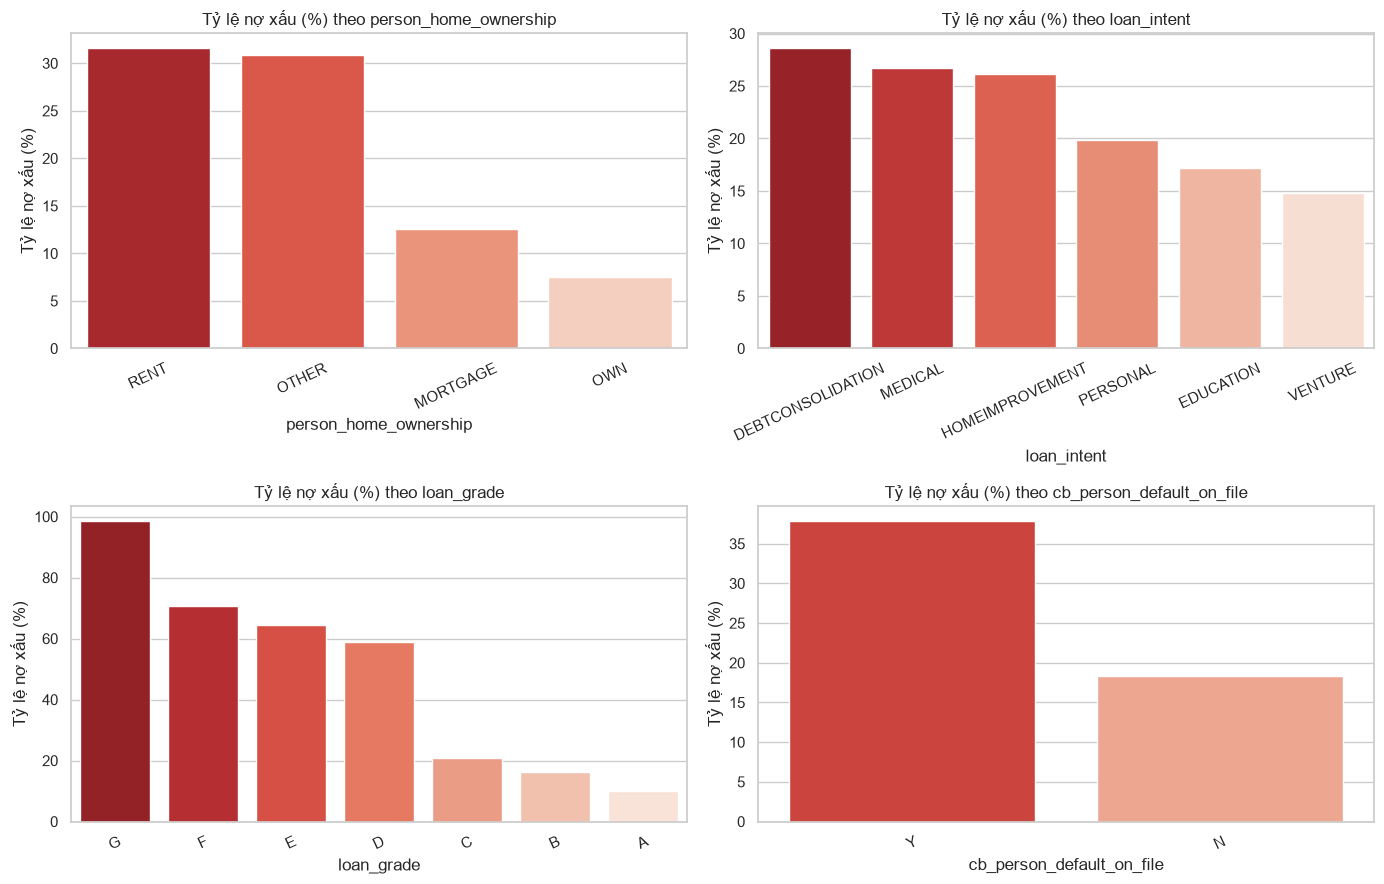

In [11]:
cat_cols = ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flatten(), cat_cols):
    rate = df.groupby(col)["loan_status"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.index, y=rate.values, hue=rate.index, ax=ax, palette="Reds_r", legend=False)
    ax.set_title(f"Tỷ lệ nợ xấu (%) theo {col}")
    ax.set_ylabel("Tỷ lệ nợ xấu (%)")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.savefig("../reports/figures/eda_categorical_default_rate.png", dpi=150, bbox_inches="tight")
plt.show()

> **Nhận xét Phần 5**:
> - `loan_grade`: Tỷ lệ nợ xấu tăng rất rõ từ hạng `A` đến `G` → biến dự báo rất mạnh.
> - `person_home_ownership`: Nhóm `RENT` có tỷ lệ nợ xấu cao nhất.
> - `cb_person_default_on_file`: Khách hàng từng vỡ nợ (`Y`) có rủi ro cao hơn hẳn nhóm `N`.
> - `loan_intent`: Mục đích vay `DEBTCONSOLIDATION` có tỷ lệ nợ xấu cao nhất.

## 6. Ma trận tương quan giữa các biến số (Correlation Heatmap)
Kiểm tra mối tương quan tuyến tính giữa 7 biến số với nhau (phát hiện đa cộng tuyến) và với biến mục tiêu `loan_status`.

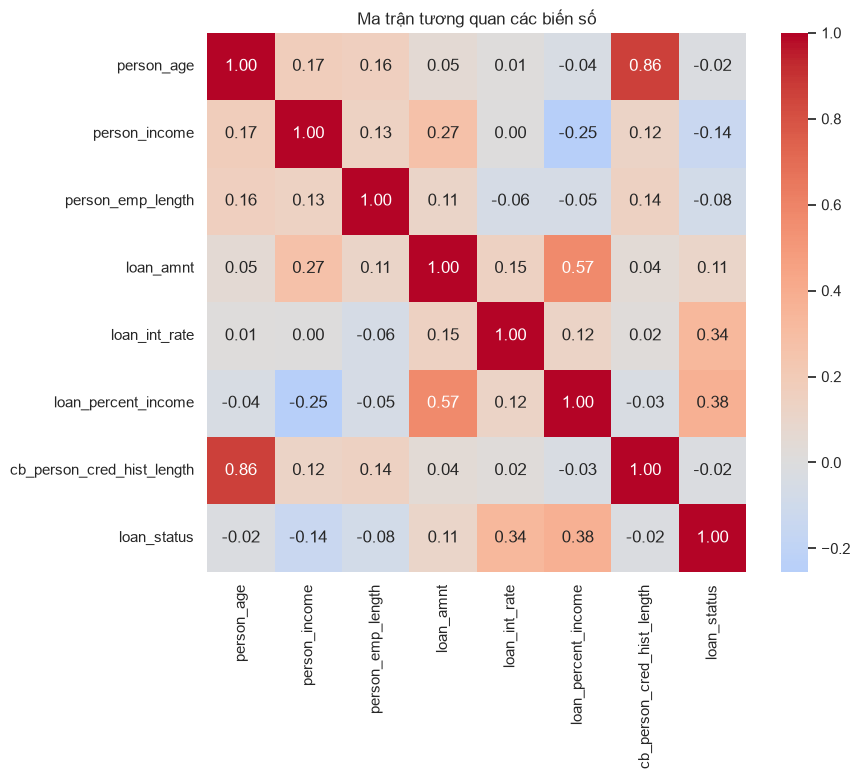

In [12]:
plt.figure(figsize=(9, 7))
corr = df[num_cols + ["loan_status"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Ma trận tương quan các biến số")
plt.savefig("../reports/figures/eda_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

> **Nhận xét Phần 6**:
> - Các biến tương quan dương mạnh nhất với `loan_status`: `loan_percent_income` (`0.38`), `loan_int_rate` (`0.34`).
> - Cặp biến có tương quan cao với nhau: `person_age` và `cb_person_cred_hist_length` (`~0.86`) → lưu ý hiện tượng đa cộng tuyến khi diễn giải hệ số của Logistic Regression.

## 7. Tổng kết EDA & Kế hoạch Tiền xử lý (Bước 3)

| Vấn đề phát hiện trong EDA | Giải pháp áp dụng ở Bước 3 |
|---|---|
| Dòng trùng lặp hoàn toàn | Xóa bằng `drop_duplicates()` trước khi chia Train/Test |
| Lỗi nhập liệu phi logic (`person_age > 100`, `person_emp_length > 60`) | Loại bỏ hoặc gán `NaN` trước bước chia tập |
| Giá trị khuyết (`person_emp_length`, `loan_int_rate`) | `SimpleImputer(strategy="median")` bên trong Pipeline |
| Ngoại trị tài chính lệch phải mạnh | `IQRClipper` + `RobustScaler` (fit chỉ trên tập Train) |
| Biến phân loại (4 cột) | `OneHotEncoder(handle_unknown="ignore")` |
| Mất cân bằng nhãn (~21.8% nợ xấu) | `SMOTE` bên trong `imblearn.pipeline.Pipeline` (chỉ chạy trên Train fold) |